In [3]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent
DATA = ROOT / "all_datasets"
RESULTS = ROOT / "results" / "lab08"
RESULTS.mkdir(parents=True, exist_ok=True)

In [ ]:
#Q1: Verify the evolutionary loop

# Simple GA to minimise f(x) = (x-3)^2. If this can't find x = 3,
# the loop itself is broken, so it's a good sanity check before using real data.
def ga_scalar(seed=42, pop_size=40, generations=80, n_elite=2):
    rng = np.random.default_rng(seed)               # fixed seed so the result is repeatable
    population = rng.uniform(-10, 10, pop_size)     # random starting guesses

    for _ in range(generations):
        fitness = (population - 3) ** 2             # lower is better

        # elitism: the best few go straight into the next generation untouched
        elite = population[np.argsort(fitness)[:n_elite]]

        # tournament selection: pick 3 random individuals, the best one becomes a parent
        contestants = rng.integers(0, pop_size, size=(pop_size, 3))
        winners = fitness[contestants].argmin(axis=1)
        parents = population[contestants[np.arange(pop_size), winners]]

        # blend crossover: each pair of parents mixes into two children
        a, b = parents[0::2], parents[1::2]
        alpha = rng.random(len(a))
        children = np.r_[alpha * a + (1 - alpha) * b,
                         alpha * b + (1 - alpha) * a][: pop_size - n_elite]

        # gaussian mutation: small random nudge so the search doesn't get stuck
        children += rng.normal(0, 0.15, len(children))

        # next generation = elites + children
        population = np.r_[elite, children]

    best = population[np.argmin((population - 3) ** 2)]
    return best, (best - 3) ** 2


x_best, f_best = ga_scalar()
print(f"Best x = {x_best:.6f}   f(x) = {f_best:.8f}")

Best x = 2.999989   f(x) = 0.00000000


In [5]:
#Q2: Prepare the regression task

# load the insurance data
insurance = pd.read_csv(DATA / "lab08-insurance.csv")

# predictors: age, bmi, children, plus smoker turned into 0/1
X = insurance[["age", "bmi", "children"]].assign(smoker=(insurance.smoker == "yes").astype(float))
y = insurance.charges.to_numpy()

# 80/20 split with seed 42
train, test = train_test_split(insurance.index, test_size=0.20, random_state=42)

# save which row went where so the split can be checked later
pd.Series(np.where(insurance.index.isin(test), "test", "train"), name="split") \
    .rename_axis("row_id").to_csv(RESULTS / "split.csv")

# standardise using TRAINING stats only (otherwise test info leaks into training)
scaler = StandardScaler().fit(X.loc[train])
X_train, X_test = scaler.transform(X.loc[train]), scaler.transform(X.loc[test])
y_train, y_test = y[train], y[test]

print({"rows": len(insurance), "train": len(train), "test": len(test), "predictors": list(X.columns)})

{'rows': 1338, 'train': 1070, 'test': 268, 'predictors': ['age', 'bmi', 'children', 'smoker']}


In [6]:
#Q3: Chromosome, fitness and operators

# Chromosome = 5 genes: [intercept, age, bmi, children, smoker]
# Fitness = training MSE (lower is better)
def run_ga(seed, pop_size=100, generations=160, mutation_rate=0.15, mutation_scale=0.25, n_elite=4):
    rng = np.random.default_rng(seed)
    n_genes = X_train.shape[1] + 1

    # random start, with intercepts centred near the average charge so it doesn't start miles away
    population = rng.normal(0, 5000, size=(pop_size, n_genes))
    population[:, 0] += y_train.mean()

    # mutation step size per gene (intercept gets a bigger one)
    gene_scale = np.r_[2000, np.repeat(1000, n_genes - 1)]

    # fitness: training MSE for every individual at once
    def training_mse(individuals):
        predictions = individuals[:, [0]] + individuals[:, 1:] @ X_train.T
        return ((predictions - y_train) ** 2).mean(axis=1)

    best, best_mse, history = None, np.inf, []
    started = time.perf_counter()

    for _ in range(generations):
        fitness = training_mse(population)

        # keep track of the best-so-far, used later for the convergence plot
        if fitness.min() < best_mse:
            best_mse, best = fitness.min(), population[fitness.argmin()].copy()
        history.append(best_mse)

        # elitism
        elite = population[np.argsort(fitness)[:n_elite]]

        # tournament selection (size 3)
        contestants = rng.integers(0, pop_size, size=(pop_size, 3))
        winners = fitness[contestants].argmin(axis=1)
        parents = population[contestants[np.arange(pop_size), winners]]

        # blend crossover; alpha goes slightly outside 0-1 so children can land beyond the parents
        a, b = parents[0::2], parents[1::2]
        alpha = rng.uniform(-0.1, 1.1, size=(len(a), 1))
        children = np.vstack([alpha * a + (1 - alpha) * b,
                              alpha * b + (1 - alpha) * a])[: pop_size - n_elite]

        # gaussian mutation, only on a random 15% of genes
        mutate = rng.random(children.shape) < mutation_rate
        children += mutate * rng.normal(0, mutation_scale, size=children.shape) * gene_scale

        population = np.vstack([elite, children])

    # score the best chromosome on the unseen test set
    test_rmse = mean_squared_error(y_test, best[0] + X_test @ best[1:]) ** 0.5
    return {"seed": seed, "train_rmse": best_mse ** 0.5, "test_rmse": test_rmse,
            "runtime_s": time.perf_counter() - started, "coefficients": best,
            "history": np.sqrt(history)}


# quick single run just to check it works
trial = run_ga(seed=1)
print(f"seed 1: train RMSE {trial['train_rmse']:.1f} | test RMSE {trial['test_rmse']:.1f} | {trial['runtime_s']:.2f} s")
print("Best chromosome [intercept, age, bmi, children, smoker]:", trial["coefficients"].round(1))

seed 1: train RMSE 6113.1 | test RMSE 5829.4 | 0.19 s
Best chromosome [intercept, age, bmi, children, smoker]: [13346.1  3616.3  1978.4   519.2  9559.3]


In [7]:
#Q4: Ten independent seeds

# helper to turn a list of run results into a clean table
def run_table(runs):
    return pd.DataFrame(runs)[["seed", "train_rmse", "test_rmse", "runtime_s"]]


# run seeds 1 to 10 and save the table
runs = [run_ga(seed) for seed in range(1, 11)]
results = run_table(runs)
results.to_csv(RESULTS / "ga_10_runs.csv", index=False)
display(results.round(3))

# median = typical result, SD = how much it changes between seeds
print(f"Median test RMSE {results.test_rmse.median():.2f} | SD across seeds {results.test_rmse.std():.4f}")

,seed,train_rmse,test_rmse,runtime_s
0,1,6113.068,5829.378,0.131
1,2,6113.068,5829.379,0.060
2,3,6113.068,5829.378,0.069
3,4,6113.068,5829.377,0.055
4,5,6113.068,5829.381,0.060
5,6,6113.068,5829.375,0.079
6,7,6113.068,5829.377,0.072
7,8,6113.068,5829.380,0.069
8,9,6113.068,5829.380,0.064
9,10,6113.068,5829.380,0.066


Median test RMSE 5829.38 | SD across seeds 0.0019


OLS test RMSE: 5829.38
OLS coefficients:    [3616.3 1978.4  519.2 9559.3]
Median GA coefficients: [3616.3 1978.4  519.2 9559.3]


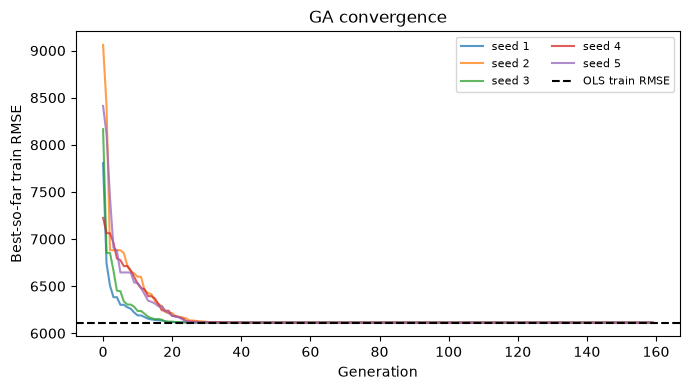

In [8]:
# Q5: Compare with least squares

# OLS on exactly the same split and scaling, so the comparison is fair
ols = LinearRegression().fit(X_train, y_train)
ols_test_rmse = mean_squared_error(y_test, ols.predict(X_test)) ** 0.5
ols_train_rmse = mean_squared_error(y_train, ols.predict(X_train)) ** 0.5

print("OLS test RMSE:", round(ols_test_rmse, 2))
print("OLS coefficients:   ", ols.coef_.round(1))
print("Median GA coefficients:", np.median([r["coefficients"][1:] for r in runs], axis=0).round(1))

# convergence plot: best-so-far train RMSE for 5 seeds vs the OLS floor
fig, ax = plt.subplots(figsize=(7, 4))
for r in runs[:5]:
    ax.plot(r["history"], alpha=0.75, label=f"seed {r['seed']}")
ax.axhline(ols_train_rmse, linestyle="--", color="black", label="OLS train RMSE")
ax.set(xlabel="Generation", ylabel="Best-so-far train RMSE", title="GA convergence")
ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS / "convergence.png", dpi=160)
plt.show()

In [9]:
#Q6: Sensitivity study (population 40)

# same ten seeds, but with a smaller population
small = run_table([run_ga(seed, pop_size=40) for seed in range(1, 11)])
small.to_csv(RESULTS / "ga_sensitivity_pop40.csv", index=False)

# one summary table: GA (pop 100), GA (pop 40) and OLS side by side
summary = pd.DataFrame([
    {"method": "GA pop=100", "median_test_rmse": results.test_rmse.median(),
     "sd_test_rmse": results.test_rmse.std(), "median_runtime_s": results.runtime_s.median()},
    {"method": "GA pop=40", "median_test_rmse": small.test_rmse.median(),
     "sd_test_rmse": small.test_rmse.std(), "median_runtime_s": small.runtime_s.median()},
    {"method": "OLS", "median_test_rmse": ols_test_rmse,
     "sd_test_rmse": 0.0, "median_runtime_s": np.nan},  # OLS is deterministic, no spread, runtime not measured
])
summary.to_csv(RESULTS / "summary.csv", index=False)
display(summary.round(4))

# check all the files the lab wants were actually saved
print("Saved:", sorted(p.name for p in RESULTS.iterdir()))

,method,median_test_rmse,sd_test_rmse,median_runtime_s
0,GA pop=100,5829.3787,0.0019,0.0674
1,GA pop=40,5829.3819,0.0255,0.0360
2,OLS,5829.3785,0.0000,NaN


Saved: ['convergence.png', 'ga_10_runs.csv', 'ga_sensitivity_pop40.csv', 'split.csv', 'summary.csv']


## Conclusion

Across 10 seeds the GA's median test RMSE was about 5829.38 with a spread of only 0.002,
so the result is stable and not down to one lucky run. This is the same as OLS (5829.38),
but that means the GA *found* the optimum, not that it *beat* it. Least squares has an exact
closed-form answer, so nothing can do better on this objective, and OLS gets there faster and
without randomness. A smaller population (40) halved the runtime but increased the spread
(0.0255), so it depends more on the starting point. A GA would make more sense if the
objective were non-differentiable or discrete, for example minimising the number of
non-zero coefficients (feature selection) or optimising a metric like MAE with hard
constraints on the coefficients.